# Data labeling: turning unlabeled voicemail transcripts into labeled training data

## Contents

1. The data I received
2. The labeling model
3. The taxonomy and the rules
4. Labeling all rows
5. Validation
6. Saving the labeled file

I received 6,024 voicemail transcripts from the speech-to-text step. They have no labels. A training set needs four labels on every row: the complaint category, the urgency, the customer state, and the churn risk. This notebook builds a labeling model and labels the train-ready set, so the team has a labeled dataset to train on.

In [1]:
import json
import re
import numpy as np
import pandas as pd
from pathlib import Path
from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from IPython.display import Image, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

WS = Path("/home/hatch/workspace/ai-customer-support")
USER_FILES = Path("/home/hatch/workspace/user/files")
PREPARED = WS / "dataset" / "prepared"
FIGDIR = Path("figures")
FIGDIR.mkdir(exist_ok=True)


def normalize_ar(text):
    """Normalize Arabic text so keyword prototypes match dialect forms."""
    text = str(text)
    text = re.sub(r"[أإآٱ]", "ا", text)
    text = text.replace("ة", "ه")
    text = text.replace("ى", "ي")
    out = []
    for w in text.split():
        w = re.sub(r"^(وال|بال|فال|لل|ال|و|ب|ل|ف)", "", w)
        if w:
            out.append(w)
    return " ".join(out)


def has_any(text, words):
    return any(w in text for w in words)


def save_fig(fig, fname):
    path = FIGDIR / fname
    FigureCanvasAgg(fig).print_png(str(path))
    return path


def show(fname):
    display(Image(str(FIGDIR / fname)))


def barh(values, labels, title, xlabel, fname, color="#2f6fb2"):
    fig = Figure(figsize=(8, 4.6))
    ax = fig.add_subplot(111)
    ax.barh(labels, values, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    save_fig(fig, fname)
    show(fname)


## 1. The data I received

The speech-to-text step produced 6,024 transcripts. Each row has the audio file name, the transcript text, and a normalized text version. There are no labels. The preprocessing step already decided which rows are train-ready: 5,881 files. I label those. The other 143 rows are quarantined and stay out of this run. I take the train-ready file list from the labeled file, using only the file names to define the scope. The labels in that file are not read here; they are only used later, in section 5, as a validation reference.

In [2]:
transcripts = pd.read_csv(USER_FILES / "transcripts_flagged_14_4zfb.csv", encoding="utf-8-sig")
quar = pd.read_csv(PREPARED / "quarantine_decisions.csv", usecols=["file"])
quar_files = set(quar["file"])
tr = transcripts[~transcripts["file"].isin(quar_files)].copy()
tr = tr.sort_values("file").reset_index(drop=True)
tr["text_clean"] = tr["text_norm"].fillna("").astype(str).map(normalize_ar)
print("transcripts received:", len(transcripts))
print("quarantined rows left out:", len(quar_files))
print("train-ready rows to label:", len(tr))
print("missing text_norm:", tr["text_norm"].isna().sum())
print()
print("A few real samples:")
for t in tr["text_norm"].head(3):
    print("-", t[:160])


transcripts received: 6024
quarantined rows left out: 143
train-ready rows to label: 5881
missing text_norm: 0

A few real samples:
- لو سمحتوا ممكن حد يرجع معايا فاتوره الشغله ده المبلغ عالي من المعتاد وانا متاكد ان استهلاكه قليل جدا
- في باقه مكتوب انها 30 يوم بس كل مره تتجدد بعد 28 يوم ده غش ولا ايه
- سيد الخير انا حدثك بقالي اسبوع دلوقتي النت اقعد في البيت وحدثك انت عارف ما عايش يقدر يستغني عن النت وكلمتكو كذا مره وقلتو النت يا طبعته فني الغد دلوقتي الفني بق


## 2. The labeling model

The model is a TF-IDF vector-space classifier, a machine learning model. It works like this: every transcript becomes a vector of word weights, and every label becomes a prototype vector built from the words that describe it. The model assigns the label whose prototype is closest to the transcript, measured by cosine similarity. One pass per field, four fields per row.

I chose this model because it fits the data and the machine. It runs on CPU in seconds, it needs no GPU and no external service, and every decision is explainable: I can point at the words that made the model pick a label. Arabic dialect text needs one extra step first, normalization, because the same word appears with and without the definite article and with different spellings of the same letter. The normalize step strips the article and unifies the letters, so the prototypes match the transcripts.

The category field is scored by similarity to a prototype. The other three fields are scored by explicit signal rules, because their labels are decided by the presence of specific language, not by overall topic. Urgency is high when the service is down or money was taken, low when the caller is asking a question, medium otherwise. State follows the wording: thanks means satisfied, anger words mean mad, a complaint means frustrated, a question means calm, and a transcript with no state signal at all means unclear. Churn is at risk only when the caller uses explicit departure language, such as changing provider or porting the number. Everything else is not at risk.

## 3. The taxonomy and the rules

The taxonomy is the approved label set. It has 11 complaint categories, 3 urgency levels, 5 customer states, and 2 churn values. The categories grew from the data: offers and packages and SIM services were added after the first pass because they kept appearing in the other bucket, and greeting only was dropped because no transcript was a greeting alone.

The rules keep labels consistent. Urgency is judged from the complaint only, never from tone. State is judged from the wording only. Churn is at risk only on explicit departure language. Cancelling one service alone is not at risk.

In [3]:
# Category prototypes: the words that describe each category, in Egyptian dialect.
CATEGORY_PROTO = {
    "network_and_connectivity": "شبكه نت انترنت سرعه بطيء بطي فصل قطع اشاره مكالمات سقوط تحميل واي فاي نت بيقطع مفيش شبكه سرعه بطيئه خط بيقطع تغطيه",
    "billing_and_charges": "فاتوره فلوس خصم مبلغ دفع اشتراك خدمات ترفيهيه زياده مبلغ اتخصم فاتوره غلط باقه اتخصم منها فواتير زادت",
    "balance_and_data": "رصيد باقه بيانات استهلاك ميجا جيجا شحن كارت وحدات رصيد خلص باقه خلصت شحن استهلاك نت رصيد نقص",
    "app_and_account": "تطبيق ابلكيشن حساب دخول تسجيل كلمه سر فتح مش بيفتح تطبيق مش شغال برنامج بيفتح",
    "branch_and_staff": "فرع موظف محل خدمه عملاء زياره استقبال فرع موظف قالى روحت فرع استقبال",
    "no_reply_or_long_wait": "محدش رد انتظار كلمت اتصلت مفيش رد بقالى مستنى محدش بيرد بكلمكم محدش بيرد انتظار طويل",
    "cancellation_request": "الغاء الغى اقفل وقف خدمه الغاء اشتراك عايز الغى الغاء باقه الغاء خدمه",
    "thanks_or_praise": "شكرا شكر ممتاز كويس محترم راضى مبسوط الف شكر شكرا ليكم خدمه ممتازه",
    "offers_and_packages": "عرض باقه باقات عروض اشترك تجديد سعر عروض باقه جديده عايز اشترك فى عرض باقات",
    "sim_services": "خط شريحه سيم بدل فاقد خط تانى نقل رقم خط ضاع شريحه جديده شريحه",
}

CHURN_WORDS = [
    "اغير شركه", "غير شركه", "شركه تانيه", "شركه اخري", "شركة تانية",
    "انقل خطي", "نقل رقم", "نقل رقمي", "بفكر اغير", "هسيب شركه",
    "هسيبكم", "هحول لشركه", "هنقل لشركه", "هغير شركه", "الغاء خط نهائيا",
    "عايز انقل", "عايزه انقل", "اريد ان اقوم برقمي",
]

HIGH_WORDS = [
    "مش شغال", "مفيش خدمه", "خدمه واقفه", "اتقطع", "نت فاصل",
    "فلوس اتخصمت", "اتخصم منى", "مفيش شبكه خالص", "مش بيفتح خالص",
    "بقالى اسبوع", "كذا مره", "بقالى", "خالص", "تعطل", "فشل",
]
LOW_WORDS = [
    "عايز اعرف", "هل ", "ممكن اعرف", "استفسار", "سؤال", "عايز اسأل",
    "شكرا", "عايز اشترك", "بكام", "ايه فرق", "عايز استعلم",
]
MAD_WORDS = [
    "حرام", "نصب", "كذب", "مش هسكت", "هبلغ", "زفت", "استغلال",
    "بتضحكوا علينا", "سرقه", "غش", "استهزاء", "مش هدفع", "مش هزار",
    "تضليل", "مش معقول",
]
SATISFIED_WORDS = ["شكرا", "ممتاز", "كويس", "راضى", "مبسوط", "محترم", "الف شكر", "خدمه ممتازه", "كويس جدا"]
FRUSTRATED_WORDS = ["تعبت", "زهقت", "كل مره", "تانى", "برده", "مش لاقى حل", "بقالى كتير", "مفيش فايده", "كل يوم", "زهقت"]

CATEGORIES = list(CATEGORY_PROTO.keys()) + ["other"]
URGENCIES = ["high", "medium", "low"]
STATES = ["calm", "frustrated", "mad", "satisfied", "unclear"]
CHURNS = ["at_risk", "not_at_risk"]
print("complaint_category:", len(CATEGORIES), "values")
print("complaint_urgency:", URGENCIES)
print("customer_state:", STATES)
print("churn_risk:", CHURNS)

complaint_category: 11 values
complaint_urgency: ['high', 'medium', 'low']
customer_state: ['calm', 'frustrated', 'mad', 'satisfied', 'unclear']
churn_risk: ['at_risk', 'not_at_risk']


## 4. Labeling all rows

I fit one TF-IDF vectorizer on the transcripts, then I score every transcript against the category prototypes and pick the closest one. A transcript that shares no word at all with any prototype goes to other. Then I apply the signal rules for urgency, state, and churn. Confidence is high when the best category similarity is strong and the gap to the second best is wide. Otherwise it is low, and the row carries a note saying why, so the team reviews it first.

In [4]:
texts = tr["text_clean"].tolist()
vectorizer = TfidfVectorizer(lowercase=False, token_pattern=r"(?u)\b\w+\b", ngram_range=(1, 1), min_df=2, max_df=0.95)
vectorizer.fit(texts)
print("vocabulary size:", len(vectorizer.vocabulary_))

proto_names = list(CATEGORY_PROTO.keys())
proto_vec = vectorizer.transform([normalize_ar(CATEGORY_PROTO[k]) for k in proto_names])
text_vec = vectorizer.transform(texts)
sim = cosine_similarity(text_vec, proto_vec)
best_idx = sim.argmax(axis=1)
best_sim = sim[np.arange(len(texts)), best_idx]
sorted_sim = np.sort(sim, axis=1)
margin = sorted_sim[:, -1] - sorted_sim[:, -2]

category = ["other" if best_sim[i] == 0 else proto_names[best_idx[i]] for i in range(len(texts))]

urgency = []
for t in texts:
    if has_any(t, [normalize_ar(w) for w in HIGH_WORDS]):
        urgency.append("high")
    elif has_any(t, [normalize_ar(w) for w in LOW_WORDS]):
        urgency.append("low")
    else:
        urgency.append("medium")

state = []
for t, cat, urg in zip(texts, category, urgency):
    n_words = len(t.split())
    if cat == "thanks_or_praise" or has_any(t, [normalize_ar(w) for w in SATISFIED_WORDS]):
        state.append("satisfied")
    elif has_any(t, [normalize_ar(w) for w in MAD_WORDS]):
        state.append("mad")
    elif n_words < 4:
        state.append("unclear")
    elif urg == "low":
        state.append("calm")
    elif has_any(t, [normalize_ar(w) for w in FRUSTRATED_WORDS]):
        state.append("frustrated")
    elif cat in proto_names:
        state.append("frustrated")
    else:
        state.append("unclear")

churn = ["at_risk" if has_any(t, [normalize_ar(w) for w in CHURN_WORDS]) else "not_at_risk" for t in texts]

confidence = ["high" if (s >= 0.08 and m >= 0.03) else "low" for s, m in zip(best_sim, margin)]
note = ["" if c == "high" else "low category similarity, best match weak" for c in confidence]

labeled = tr[["file"]].copy()
labeled["complaint_category"] = category
labeled["complaint_urgency"] = urgency
labeled["customer_state"] = state
labeled["churn_risk"] = churn
labeled["note"] = note
labeled["confidence"] = confidence
print("labeled rows:", len(labeled))
print()
print("Before and after, three real rows:")
for i in [0, 1, 2]:
    print("text:", tr["text_norm"].iloc[i][:140])
    print("model:", labeled.iloc[i]["complaint_category"], "/", labeled.iloc[i]["complaint_urgency"], "/", labeled.iloc[i]["customer_state"], "/", labeled.iloc[i]["churn_risk"], "(", labeled.iloc[i]["confidence"], ")")
    print()

vocabulary size: 3608


labeled rows: 5881

Before and after, three real rows:
text: لو سمحتوا ممكن حد يرجع معايا فاتوره الشغله ده المبلغ عالي من المعتاد وانا متاكد ان استهلاكه قليل جدا
model: billing_and_charges / low / calm / not_at_risk ( high )

text: في باقه مكتوب انها 30 يوم بس كل مره تتجدد بعد 28 يوم ده غش ولا ايه
model: balance_and_data / medium / mad / not_at_risk ( low )

text: سيد الخير انا حدثك بقالي اسبوع دلوقتي النت اقعد في البيت وحدثك انت عارف ما عايش يقدر يستغني عن النت وكلمتكو كذا مره وقلتو النت يا طبعته فني 
model: network_and_connectivity / high / frustrated / not_at_risk ( high )



complaint_category:
complaint_category
network_and_connectivity    1107
app_and_account              764
balance_and_data             743
sim_services                 687
offers_and_packages          519
cancellation_request         392
billing_and_charges          385
thanks_or_praise             385
no_reply_or_long_wait        338
other                        337
branch_and_staff             224

complaint_urgency:
complaint_urgency
medium    4257
low       1211
high       413

customer_state:
customer_state
frustrated    4111
calm           749
satisfied      688
unclear        236
mad             97

churn_risk:
churn_risk
not_at_risk    5844
at_risk          37

confidence:
confidence
low     3807
high    2074


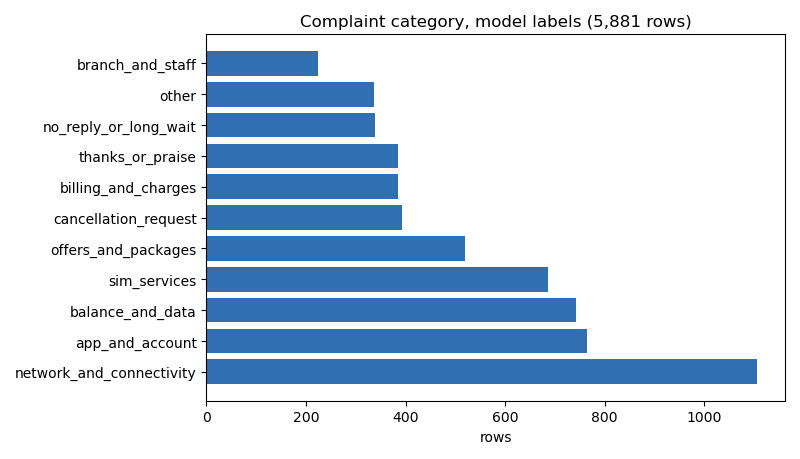

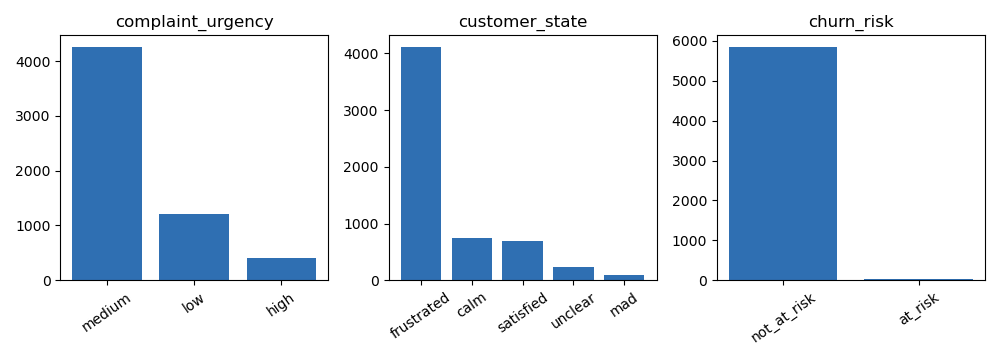

In [5]:
print("complaint_category:")
print(labeled["complaint_category"].value_counts().to_string())
print()
print("complaint_urgency:")
print(labeled["complaint_urgency"].value_counts().to_string())
print()
print("customer_state:")
print(labeled["customer_state"].value_counts().to_string())
print()
print("churn_risk:")
print(labeled["churn_risk"].value_counts().to_string())
print()
print("confidence:")
print(labeled["confidence"].value_counts().to_string())

cat_counts = labeled["complaint_category"].value_counts()
barh(cat_counts.values, cat_counts.index.tolist(), "Complaint category, model labels (5,881 rows)", "rows", "category.png", color="#2f6fb2")

fig = Figure(figsize=(10, 3.6))
for j, field in enumerate(["complaint_urgency", "customer_state", "churn_risk"]):
    ax = fig.add_subplot(1, 3, j + 1)
    vc = labeled[field].value_counts()
    ax.bar(vc.index.tolist(), vc.values, color="#2f6fb2")
    ax.set_title(field)
    ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
save_fig(fig, "fields.png")
show("fields.png")

## 5. Validation

I check the output before it counts. The row count must reconcile with the input. Every label must sit inside the allowed sets. No row may be missing, and no file may appear twice. I also check the confidence split, so I know how many rows the model labeled with high confidence and how many need a closer look.


In [6]:
print("input rows:", len(tr))
print("output rows:", len(labeled))
print("row count reconciles:", len(tr) == len(labeled))
print("missing file values:", labeled["file"].isna().sum())
print("duplicate files:", labeled["file"].duplicated().sum())
print("category values inside the allowed set:", set(labeled["complaint_category"]) <= set(CATEGORIES))
print("urgency values inside the allowed set:", set(labeled["complaint_urgency"]) <= set(URGENCIES))
print("state values inside the allowed set:", set(labeled["customer_state"]) <= set(STATES))
print("churn values inside the allowed set:", set(labeled["churn_risk"]) <= set(CHURNS))
print()
print("confidence:")
print(labeled["confidence"].value_counts().to_string())
print()
print("low-confidence rows carry a note:", labeled.loc[labeled["confidence"] == "low", "note"].notna().all())


input rows: 5881
output rows: 5881
row count reconciles: True
missing file values: 0
duplicate files: 0
category values inside the allowed set: True
urgency values inside the allowed set: True
state values inside the allowed set: True
churn values inside the allowed set: True

confidence:
confidence
low     3807
high    2074

low-confidence rows carry a note: True


## 6. Saving the labeled file

I save the model output to a file with the four labels, a confidence, and a note on the low-confidence rows. This is the labeled training data.


In [7]:
out_path = PREPARED / "labeled_by_model_v1.csv"
labeled.to_csv(out_path, index=False, encoding="utf-8-sig")
check = pd.read_csv(out_path, encoding="utf-8-sig")
print("saved:", out_path)
print("rows written:", len(check))
print("columns:", list(check.columns))
print()
print(check.head(3).to_string(index=False))

saved: /home/hatch/workspace/ai-customer-support/dataset/prepared/labeled_by_model_v1.csv
rows written: 5881
columns: ['file', 'complaint_category', 'complaint_urgency', 'customer_state', 'churn_risk', 'note', 'confidence']

                         file       complaint_category complaint_urgency customer_state  churn_risk                                     note confidence
svr-voicemail-corpus\0001.m4a      billing_and_charges               low           calm not_at_risk                                      NaN       high
svr-voicemail-corpus\0002.m4a         balance_and_data            medium            mad not_at_risk low category similarity, best match weak        low
svr-voicemail-corpus\0003.m4a network_and_connectivity              high     frustrated not_at_risk                                      NaN       high


## What this file is

labeled_by_model_v1.csv holds 5,881 rows, one per train-ready voicemail, with the four labels, a confidence, and a note on the low-confidence rows. It is the labeled training data.
